In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Python is ready!")
print("Pandas version:", pd.__version__)

Python is ready!
Pandas version: 3.0.3


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Matplotlib and Seaborn are ready!")
print("All libraries imported successfully!")

Matplotlib and Seaborn are ready!
All libraries imported successfully!


In [3]:
data = {
    "Order_ID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 102],
    "Product": ["Laptop", "Phone", "Tablet", "Laptop", None,
                "Phone", "Tablet", "Laptop", "Phone", "Tablet", "Phone"],
    "Sales": [50000, 20000, 15000, 55000, 18000,
              None, 16000, 52000, 22000, 17000, 20000],
    "Quantity": [2, 3, 1, 2, 2, 4, None, 2, 3, 1, 3],
    "City": ["Delhi", "Mumbai", "Chennai", "Delhi", "Pune",
             "Mumbai", "Chennai", "Delhi", "Mumbai", "Pune", "Mumbai"]
}

df = pd.DataFrame(data)

df

,Order_ID,Product,Sales,Quantity,City
0,101,Laptop,50000.0,2.0,Delhi
1,102,Phone,20000.0,3.0,Mumbai
2,103,Tablet,15000.0,1.0,Chennai
3,104,Laptop,55000.0,2.0,Delhi
4,105,NaN,18000.0,2.0,Pune
5,106,Phone,NaN,4.0,Mumbai
6,107,Tablet,16000.0,NaN,Chennai
7,108,Laptop,52000.0,2.0,Delhi
8,109,Phone,22000.0,3.0,Mumbai
9,110,Tablet,17000.0,1.0,Pune


In [2]:
import pandas as pd

print("Pandas is ready!")


Pandas is ready!


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (11, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  11 non-null     int64  
 1   Product   10 non-null     str    
 2   Sales     10 non-null     float64
 3   Quantity  10 non-null     float64
 4   City      11 non-null     str    
dtypes: float64(2), int64(1), str(2)
memory usage: 691.0 bytes

First 5 Rows:


,Order_ID,Product,Sales,Quantity,City
0,101,Laptop,50000.0,2.0,Delhi
1,102,Phone,20000.0,3.0,Mumbai
2,103,Tablet,15000.0,1.0,Chennai
3,104,Laptop,55000.0,2.0,Delhi
4,105,NaN,18000.0,2.0,Pune



Missing Values:
Order_ID    0
Product     1
Sales       1
Quantity    1
City        0
dtype: int64

Duplicate Rows:
1


In [5]:
# Make a copy of the original dataset
df_clean = df.copy()

# Fill missing product names
df_clean["Product"] = df_clean["Product"].fillna("Unknown")

# Fill missing sales with the median sales value
df_clean["Sales"] = df_clean["Sales"].fillna(
    df_clean["Sales"].median()
)

# Fill missing quantity with the median quantity
df_clean["Quantity"] = df_clean["Quantity"].fillna(
    df_clean["Quantity"].median()
)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Display cleaned dataset
display(df_clean)

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())

,Order_ID,Product,Sales,Quantity,City
0,101,Laptop,50000.0,2.0,Delhi
1,102,Phone,20000.0,3.0,Mumbai
2,103,Tablet,15000.0,1.0,Chennai
3,104,Laptop,55000.0,2.0,Delhi
4,105,Unknown,18000.0,2.0,Pune
5,106,Phone,20000.0,4.0,Mumbai
6,107,Tablet,16000.0,2.0,Chennai
7,108,Laptop,52000.0,2.0,Delhi
8,109,Phone,22000.0,3.0,Mumbai
9,110,Tablet,17000.0,1.0,Pune


Missing values after cleaning:
Order_ID    0
Product     0
Sales       0
Quantity    0
City        0
dtype: int64

Duplicate rows after cleaning:
0


Statistical Summary:


,Sales,Quantity
count,10.000000,10.000000
mean,28500.000000,2.200000
std,16614.919667,0.918937
min,15000.000000,1.000000
25%,17250.000000,2.000000
50%,20000.000000,2.000000
75%,43000.000000,2.750000
max,55000.000000,4.000000


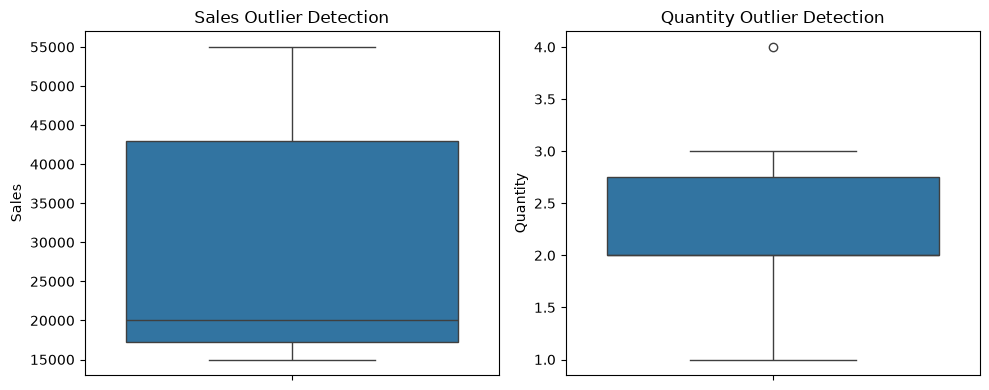

In [8]:
# Check statistical summary of numerical columns
print("Statistical Summary:")
display(df_clean[["Sales", "Quantity"]].describe())

# Create boxplots to identify possible outliers
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df_clean["Sales"])
plt.title("Sales Outlier Detection")

plt.subplot(1, 2, 2)
sns.boxplot(y=df_clean["Quantity"])
plt.title("Quantity Outlier Detection")

plt.tight_layout()
plt.show()

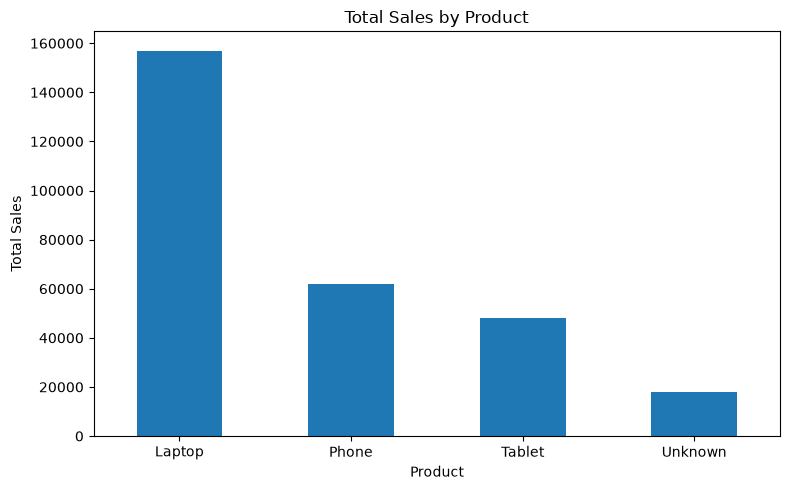

In [9]:
# Calculate total sales for each product
product_sales = df_clean.groupby("Product")["Sales"].sum()

# Create bar chart
plt.figure(figsize=(8, 5))
product_sales.plot(kind="bar")

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

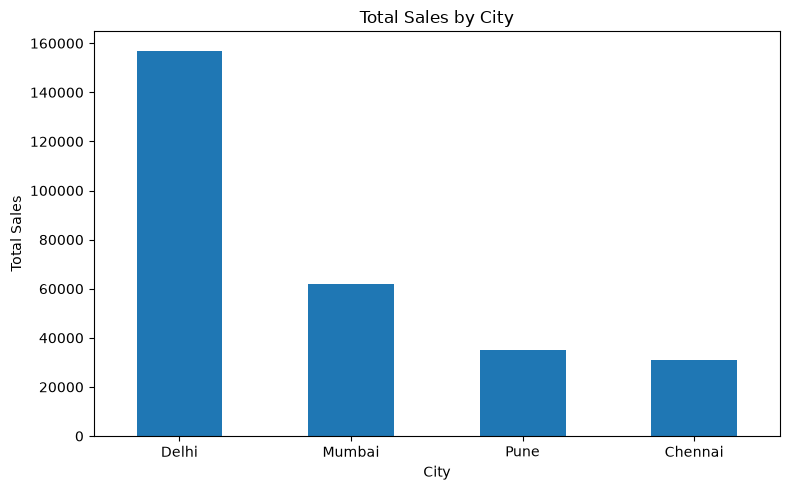

In [10]:
city_sales = df_clean.groupby("City")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
city_sales.plot(kind="bar")

plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
print("Total sales by product:")
print(product_sales.sort_values(ascending=False))

print("\nTotal sales by city:")
print(city_sales)

print("\nTotal sales in cleaned dataset:", df_clean["Sales"].sum())

Total sales by product:
Product
Laptop     157000.0
Phone       62000.0
Tablet      48000.0
Unknown     18000.0
Name: Sales, dtype: float64

Total sales by city:
City
Delhi      157000.0
Mumbai      62000.0
Pune        35000.0
Chennai     31000.0
Name: Sales, dtype: float64

Total sales in cleaned dataset: 285000.0


In [12]:
print("FINAL DATA QUALITY REPORT")
print("-" * 35)

print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(df_clean))

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nRemaining missing values:",
      df_clean.isnull().sum().sum())

print("\nCleaned dataset preview:")
display(df_clean.head())

FINAL DATA QUALITY REPORT
-----------------------------------
Original dataset rows: 11
Cleaned dataset rows: 10

Missing values:
Order_ID    0
Product     0
Sales       0
Quantity    0
City        0
dtype: int64

Duplicate rows: 0

Remaining missing values: 0

Cleaned dataset preview:


,Order_ID,Product,Sales,Quantity,City
0,101,Laptop,50000.0,2.0,Delhi
1,102,Phone,20000.0,3.0,Mumbai
2,103,Tablet,15000.0,1.0,Chennai
3,104,Laptop,55000.0,2.0,Delhi
4,105,Unknown,18000.0,2.0,Pune


In [13]:
df_clean.to_csv("cleaned_sales_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# Project Conclusion

## Data Cleaning
- Identified and handled missing values.
- Checked and removed exact duplicate rows.
- Inspected numerical data for potential outliers.

## Data Visualization
- Created a bar chart to compare product-wise sales.
- Created a bar chart to compare city-wise sales.
- Used visualizations to understand sales patterns.

## Final Outcome
This project demonstrates data preprocessing, data quality checks,
visualization, and basic data analysis using Python, Pandas,
Matplotlib, and Seaborn.

In [14]:
df_clean.to_csv("cleaned_sales_dataset.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!
